# Multi-Scale Kernel Search Results

Visualize and compare multi-scale DWConv configurations for ModernTCN CAN bus IDS.

In [2]:
import json
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['figure.dpi'] = 130
plt.rcParams['font.size'] = 11
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False

SEARCH_DIR = Path('../save/moderntcn/forester/ms_search')

results = json.loads((SEARCH_DIR / 'search_results.json').read_text())
histories = json.loads((SEARCH_DIR / 'search_histories.json').read_text())

print(f'Loaded {len(results)} configs')
for r in results:
    print(f"  {r['config']:<22s} kernels={str(r['kernel_sizes']):<18s} F1={r['best_val_f1']:.4f}")

Loaded 10 configs
  ms_3_5_7_9_13          kernels=[3, 5, 7, 9, 13]   F1=0.9784
  ms_3_5_9_13            kernels=[3, 5, 9, 13]      F1=0.9764
  vanilla_k13            kernels=[13]               F1=0.9744
  ms_3_9_13              kernels=[3, 9, 13]         F1=0.9728
  ms_3_9                 kernels=[3, 9]             F1=0.9701
  ms_3_13                kernels=[3, 13]            F1=0.9683
  ms_3_7_9_13            kernels=[3, 7, 9, 13]      F1=0.9679
  ms_3_7_13              kernels=[3, 7, 13]         F1=0.9677
  ms_5_13                kernels=[5, 13]            F1=0.9646
  ms_5_9_13              kernels=[5, 9, 13]         F1=0.9485


## 1. Ranking: Best Val F1 per Config

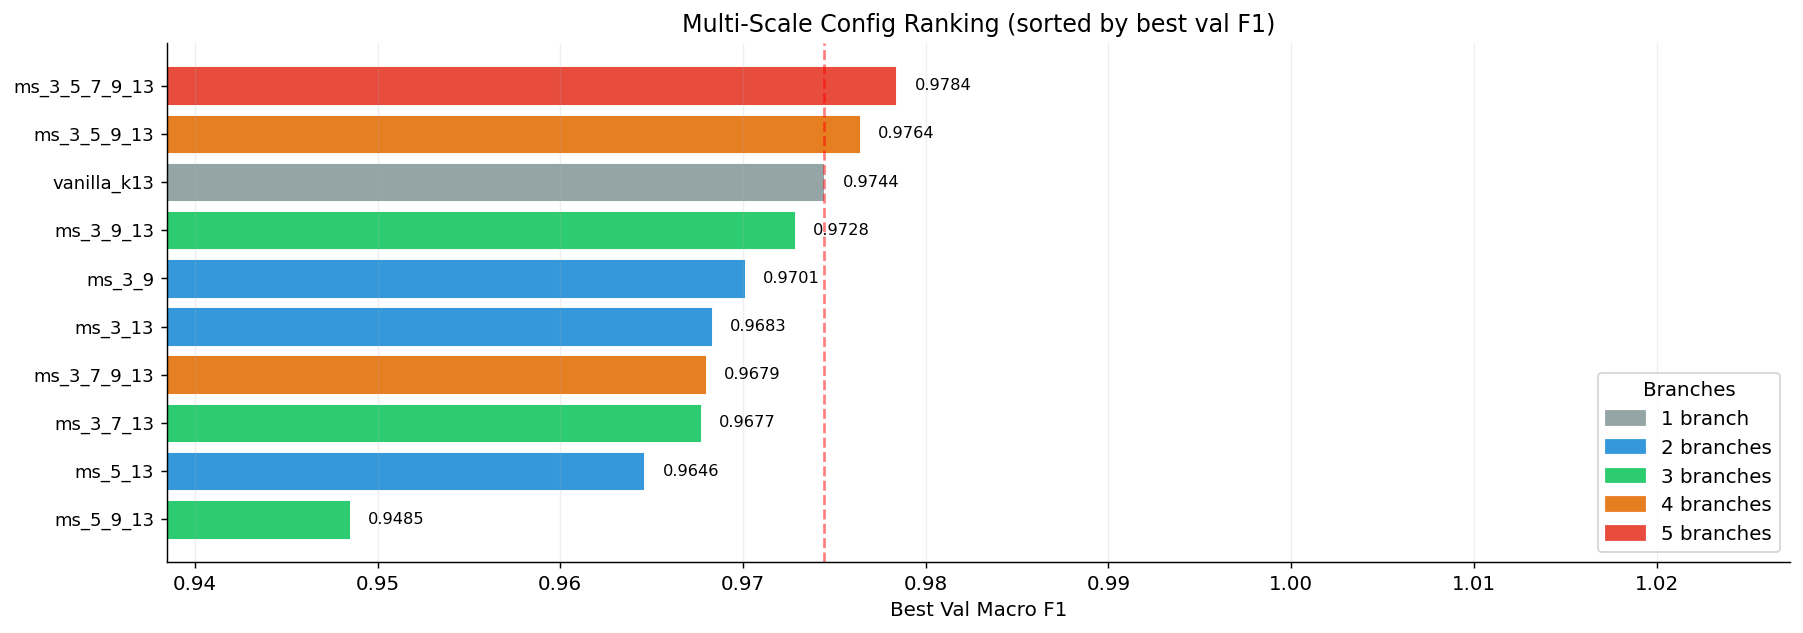

In [3]:
names = [r['config'] for r in results]
f1s = [r['best_val_f1'] for r in results]
n_branches = [len(r['kernel_sizes']) for r in results]

# Color by number of branches
cmap = {1: '#95a5a6', 2: '#3498db', 3: '#2ecc71', 4: '#e67e22', 5: '#e74c3c'}
colors = [cmap.get(nb, '#333') for nb in n_branches]

fig, ax = plt.subplots(figsize=(14, 5))
bars = ax.barh(range(len(names)), f1s, color=colors, edgecolor='white', linewidth=0.5)
ax.set_yticks(range(len(names)))
ax.set_yticklabels(names, fontsize=10)
ax.set_xlabel('Best Val Macro F1')
ax.set_title('Multi-Scale Config Ranking (sorted by best val F1)')
ax.invert_yaxis()

# Value labels
for i, (bar, f1) in enumerate(zip(bars, f1s)):
    ax.text(f1 + 0.001, i, f'{f1:.4f}', va='center', fontsize=9)

# Vanilla baseline line
vanilla_f1 = next((r['best_val_f1'] for r in results if r['config'] == 'vanilla_k13'), None)
if vanilla_f1:
    ax.axvline(vanilla_f1, color='red', linestyle='--', alpha=0.5, label=f'vanilla={vanilla_f1:.4f}')
    ax.legend()

# Legend for branches
legend_elements = [mpatches.Patch(color=cmap[k], label=f'{k} branch{"es" if k>1 else ""}') for k in sorted(cmap.keys())]
ax.legend(handles=legend_elements, loc='lower right', title='Branches')

ax.set_xlim(left=min(f1s) - 0.01)
ax.grid(axis='x', alpha=0.2)
plt.tight_layout()
plt.savefig(SEARCH_DIR / 'ranking.png', dpi=200, bbox_inches='tight')
plt.show()

## 2. Convergence Curves: All Configs

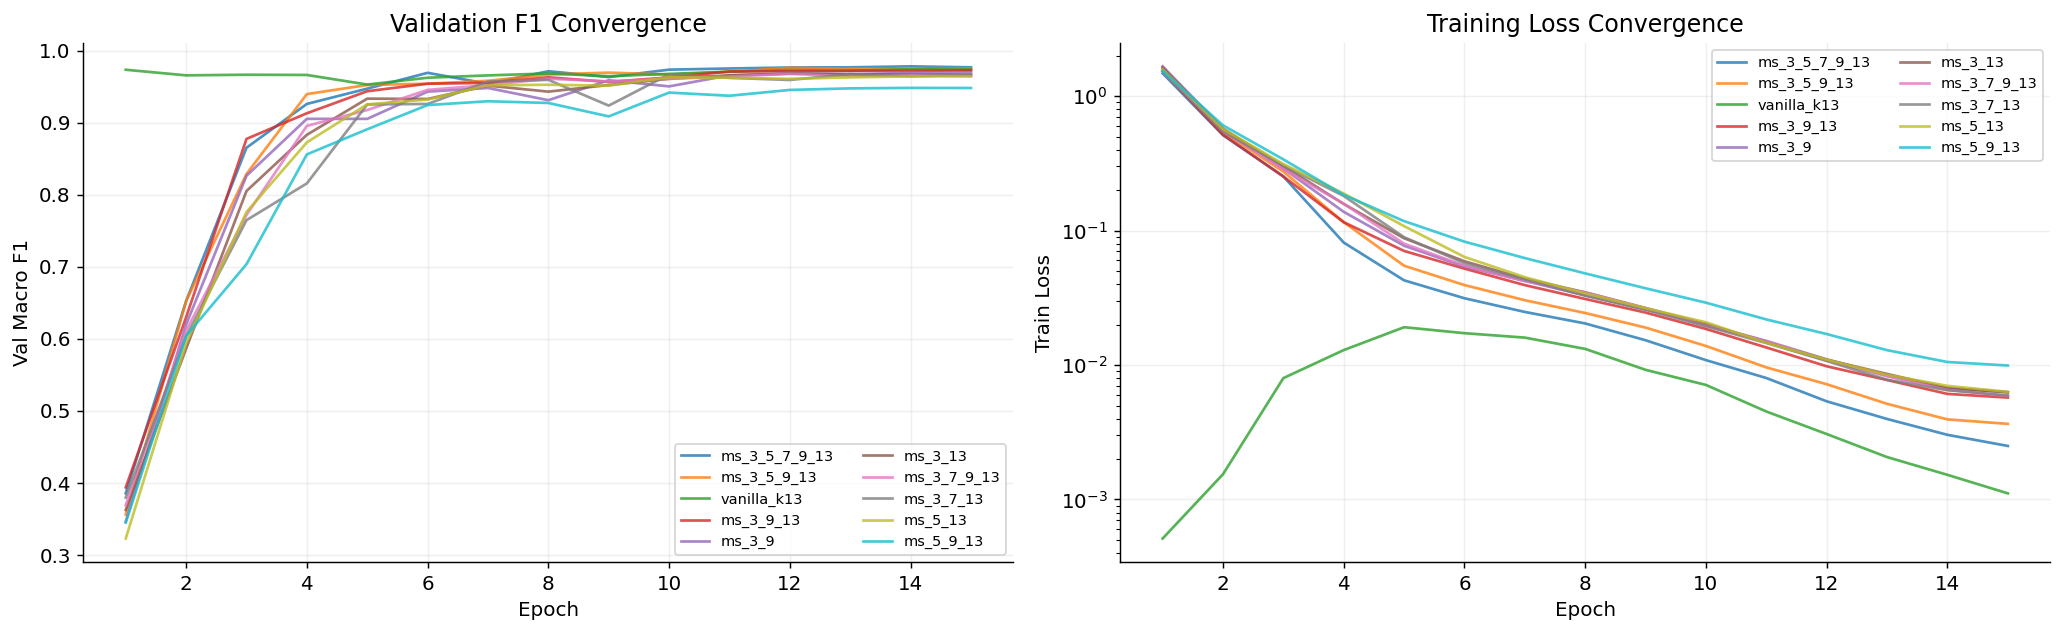

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Color each config
cmap_line = plt.cm.tab10(np.linspace(0, 1, len(histories)))

# Val F1 curves
ax = axes[0]
for i, (name, hist) in enumerate(histories.items()):
    epochs = hist['epoch']
    ax.plot(epochs, hist['val_f1'], color=cmap_line[i], linewidth=1.5,
            label=name, alpha=0.8)
ax.set_xlabel('Epoch')
ax.set_ylabel('Val Macro F1')
ax.set_title('Validation F1 Convergence')
ax.legend(fontsize=8, ncol=2, loc='lower right')
ax.grid(alpha=0.2)

# Train loss curves
ax = axes[1]
for i, (name, hist) in enumerate(histories.items()):
    epochs = hist['epoch']
    ax.plot(epochs, hist['train_loss'], color=cmap_line[i], linewidth=1.5,
            label=name, alpha=0.8)
ax.set_xlabel('Epoch')
ax.set_ylabel('Train Loss')
ax.set_title('Training Loss Convergence')
ax.set_yscale('log')
ax.legend(fontsize=8, ncol=2, loc='upper right')
ax.grid(alpha=0.2)

plt.tight_layout()
plt.savefig(SEARCH_DIR / 'convergence_all.png', dpi=200, bbox_inches='tight')
plt.show()

## 3. Number of Branches vs Performance

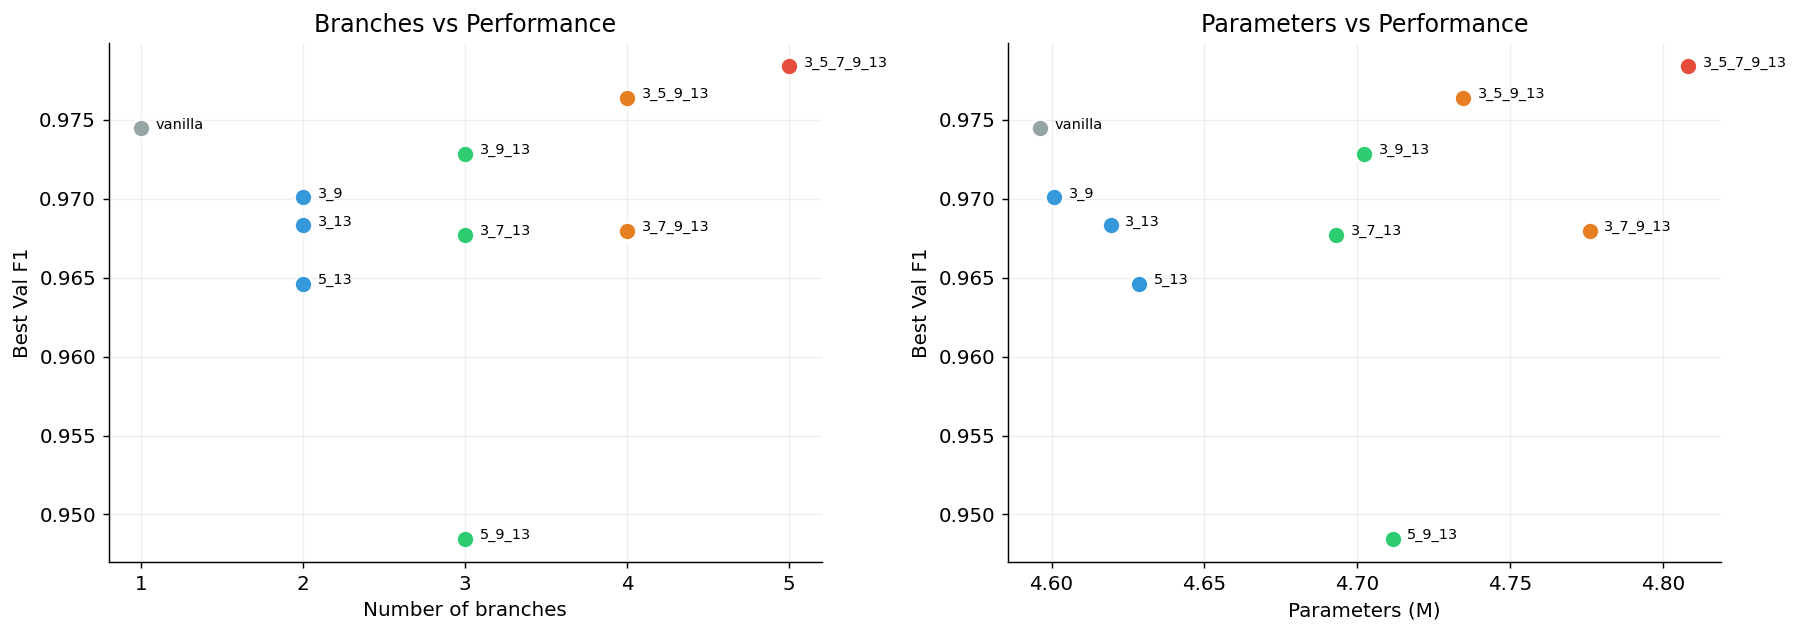

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Branches vs F1
ax = axes[0]
for r in results:
    nb = len(r['kernel_sizes'])
    ax.scatter(nb, r['best_val_f1'], s=100, color=cmap.get(nb, '#333'),
               edgecolors='white', linewidth=1.5, zorder=5)
    ax.annotate(r['config'].replace('ms_', '').replace('vanilla_k13', 'vanilla'),
                (nb, r['best_val_f1']),
                textcoords='offset points', xytext=(8, 0), fontsize=8)
ax.set_xlabel('Number of branches')
ax.set_ylabel('Best Val F1')
ax.set_title('Branches vs Performance')
ax.set_xticks([1, 2, 3, 4, 5])
ax.grid(alpha=0.2)

# Params vs F1
ax = axes[1]
for r in results:
    nb = len(r['kernel_sizes'])
    ax.scatter(r['params'] / 1e6, r['best_val_f1'], s=100, color=cmap.get(nb, '#333'),
               edgecolors='white', linewidth=1.5, zorder=5)
    ax.annotate(r['config'].replace('ms_', '').replace('vanilla_k13', 'vanilla'),
                (r['params'] / 1e6, r['best_val_f1']),
                textcoords='offset points', xytext=(8, 0), fontsize=8)
ax.set_xlabel('Parameters (M)')
ax.set_ylabel('Best Val F1')
ax.set_title('Parameters vs Performance')
ax.grid(alpha=0.2)

plt.tight_layout()
plt.savefig(SEARCH_DIR / 'branches_analysis.png', dpi=200, bbox_inches='tight')
plt.show()

## 4. Top-3 Configs Summary

In [6]:
print('=' * 65)
print('  TOP-3 CONFIGS FOR FULL TRAINING')
print('=' * 65)
for i, r in enumerate(results[:3]):
    print(f"\n  #{i+1}: {r['config']}")
    print(f"      Kernels    : {r['kernel_sizes']}")
    print(f"      Params     : {r['params']:,}")
    print(f"      Best val F1: {r['best_val_f1']:.4f}")
    print(f"      Epochs run : {r['epochs_run']}")
    print(f"      Search time: {r['time_sec']:.0f}s")

if vanilla_f1:
    best_ms = results[0]['best_val_f1']
    delta = best_ms - vanilla_f1
    print(f"\n  Improvement over vanilla: {delta:+.4f} ({delta*100:+.2f}%)")

print(f"\n  Full training command for #{1}:")
r = results[0]
ks = ' '.join(str(k) for k in r['kernel_sizes'])
ms_flag = '--multi_scale' if len(r['kernel_sizes']) > 1 else '--no_multi_scale'
print(f"  python train_moderntcn.py \\")
print(f"      --data_dir ./data/2017-subaru-forester/preprocessed \\")
print(f"      --save_folder ./save/moderntcn/forester/{r['config']}_full \\")
print(f"      --dims 128 256 --num_blocks 1 1 \\")
print(f"      --large_sizes 13 13 --small_size 5 \\")
print(f"      {ms_flag} --ms_kernel_sizes {ks} \\")
print(f"      --ffn_ratio 2 --dropout 0.1 --lr 0.001 --batch_size 256 --epochs 100")

  TOP-3 CONFIGS FOR FULL TRAINING

  #1: ms_3_5_7_9_13
      Kernels    : [3, 5, 7, 9, 13]
      Params     : 4,808,330
      Best val F1: 0.9784
      Epochs run : 15
      Search time: 1324s

  #2: ms_3_5_9_13
      Kernels    : [3, 5, 9, 13]
      Params     : 4,734,602
      Best val F1: 0.9764
      Epochs run : 15
      Search time: 1232s

  #3: vanilla_k13
      Kernels    : [13]
      Params     : 4,596,362
      Best val F1: 0.9744
      Epochs run : 15
      Search time: 1095s

  Improvement over vanilla: +0.0039 (+0.39%)

  Full training command for #1:
  python train_moderntcn.py \
      --data_dir ./data/2017-subaru-forester/preprocessed \
      --save_folder ./save/moderntcn/forester/ms_3_5_7_9_13_full \
      --dims 128 256 --num_blocks 1 1 \
      --large_sizes 13 13 --small_size 5 \
      --multi_scale --ms_kernel_sizes 3 5 7 9 13 \
      --ffn_ratio 2 --dropout 0.1 --lr 0.001 --batch_size 256 --epochs 100
